# 4. The Higgs boson, from open data, at home

In 2012 CMS recorded events with four leptons. CERN opened them. ROOT's tutorial `df103` applies the published selection; the talk ran it and found 28 candidates with a four-lepton mass between 110 and 150 GeV, fitted a Gaussian signal over an exponential background with RooFit, Clad's gradient and Minuit2, and got **m_H = 124.7 ± 1.0 GeV** at 3.1σ local significance.

This notebook does the same fit without ROOT. `data/higgs4l.npz` holds the four-lepton masses after that selection (data, and the simulated signal and ZZ background with their weights), derived from CMS open data (CC0). `data/higgs4l_roofit_reference.json` holds the RooFit result to compare with. The likelihood is seven lines of NumPy; SciPy minimises it. If JAX is installed, JAX differentiates it; if not, SciPy estimates the gradient. Either way the physics is the same: the ball of notebook 3, at scale.

In [1]:
import json, numpy as np, matplotlib.pyplot as plt
z = np.load("data/higgs4l.npz"); ref = json.load(open("data/higgs4l_roofit_reference.json"))
chans = ("4mu", "4el", "2el2mu")       # masses as float32 (the precision CMS stored), simulation kept in 70-182 GeV, one weight per simulated sample
data  = np.concatenate([z[f"data_{c}"] for c in chans]).astype(float)
sig   = np.concatenate([z[f"sig_{c}"] for c in chans]).astype(float); sig_w = np.concatenate([np.full(len(z[f"sig_{c}"]), float(z[f"sigw_{c}"])) for c in chans])
bkg   = np.concatenate([z[f"bkg_{c}"] for c in chans]).astype(float); bkg_w = np.concatenate([np.full(len(z[f"bkg_{c}"]), float(z[f"bkgw_{c}"])) for c in chans])
for c in chans: print(f"{c:7s}: {len(z[f'data_{c}']):3d} data candidates, {len(z[f'sig_{c}'])} simulated signal, {len(z[f'bkg_{c}'])} simulated ZZ")
print(len(data), "four-lepton candidates in 70-180 GeV")

4mu    :  83 data candidates, 9109 simulated signal, 30562 simulated ZZ
4el    :  44 data candidates, 5525 simulated signal, 15197 simulated ZZ
2el2mu :  91 data candidates, 12061 simulated signal, 13414 simulated ZZ
218 four-lepton candidates in 70-180 GeV


## Look at it first

The data as dots, the simulation of what the Standard Model expects as bars: ZZ production, and a Higgs boson at 125 GeV decaying to four leptons.

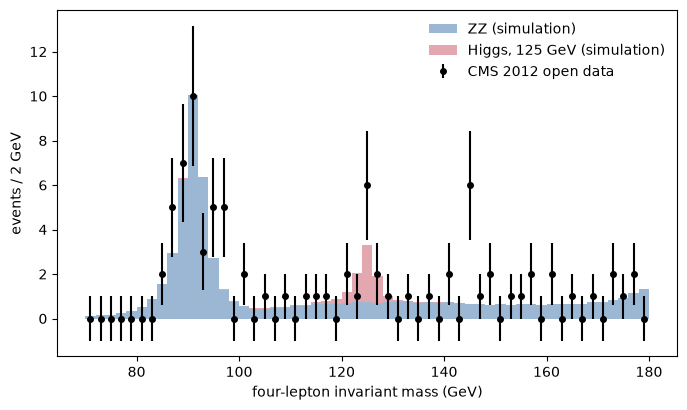

In [2]:
edges = np.arange(70, 182, 2); fig, ax = plt.subplots(figsize=(8, 4.5))
hb, _ = np.histogram(bkg, bins=edges, weights=bkg_w); hs, _ = np.histogram(sig, bins=edges, weights=sig_w); cnt, _ = np.histogram(data, bins=edges)
ax.bar(edges[:-1], hb, width=2, align="edge", color="#9bb7d4", label="ZZ (simulation)"); ax.bar(edges[:-1], hs, width=2, bottom=hb, align="edge", color="#e3a7b0", label="Higgs, 125 GeV (simulation)")
ax.errorbar(edges[:-1] + 1, cnt, yerr=np.sqrt(np.maximum(cnt, 1)), fmt="o", color="black", ms=4, label="CMS 2012 open data")
ax.set_xlabel("four-lepton invariant mass (GeV)"); ax.set_ylabel("events / 2 GeV"); ax.legend(frameon=False); plt.show()

## The likelihood

An unbinned extended likelihood on the window 110-150 GeV: a Gaussian signal whose width is the detector resolution, taken from the simulated signal and held fixed, over an exponential background. Four free parameters: the Higgs mass, the background slope, and the two yields. Each event contributes the log of the density at its mass; the Poisson term for the total count makes it "extended".

In [3]:
WLO, WHI = 110.0, 150.0; m = data[(data > WLO) & (data < WHI)]; print(len(m), "candidates in the window")
# the signal width from the simulation (weighted Gaussian fit in 115-135, as the talk does with RooFit)
from scipy.optimize import minimize
mm = (sig > 115) & (sig < 135); x_mc, w_mc = sig[mm], sig_w[mm]
nll_mc = lambda q: -np.sum(w_mc * (-0.5 * ((x_mc - q[0]) / q[1])**2 - np.log(q[1])))
mu_mc, sigma = minimize(nll_mc, [125.0, 2.0], method="Nelder-Mead").x
print(f"signal width from simulation: sigma = {sigma:.2f} GeV (RooFit got {ref['sigma_fixed']:.2f}); fixed from here on")
def nll(theta):                                # theta = (mH, slope, nsig, nbkg)
    mH, slope, ns, nb = theta
    gauss = np.exp(-0.5 * ((m - mH) / sigma)**2) / (sigma * np.sqrt(2 * np.pi))
    expo  = slope * np.exp(slope * (m - WLO)) / (np.exp(slope * (WHI - WLO)) - 1.0)   # normalised on the window
    return -np.sum(np.log(ns * gauss + nb * expo)) + (ns + nb)                         # extended: + N_expected
START = np.array([120.0, -0.01, 5.0, 15.0]); BOUNDS = [(115, 140), (-0.2, 0.2), (0, 60), (0, 200)]

28 candidates in the window


signal width from simulation: sigma = 2.69 GeV (RooFit got 2.68); fixed from here on


## Fit 1: SciPy on the NumPy likelihood

If JAX is present the gradient is JAX's; otherwise SciPy differentiates numerically. Errors come from the curvature at the minimum (a numerical Hessian). Compare with RooFit's numbers.

In [4]:
try:
    import jax, jax.numpy as jnp
    jax.config.update("jax_enable_x64", True)
    mj, sj = jnp.asarray(m), float(sigma)
    def nll_j(t):
        mH, slope, ns, nb = t
        gauss = jnp.exp(-0.5 * ((mj - mH) / sj)**2) / (sj * jnp.sqrt(2 * jnp.pi))
        expo  = slope * jnp.exp(slope * (mj - WLO)) / (jnp.exp(slope * (WHI - WLO)) - 1.0)
        return -jnp.sum(jnp.log(ns * gauss + nb * expo)) + (ns + nb)
    grad = jax.jit(jax.grad(nll_j)); hess = jax.jit(jax.hessian(nll_j)); how = "JAX gradient"
except ImportError:
    grad = None; how = "numerical gradient"
    def hess(t, h=1e-3):
        H = np.zeros((4, 4)); e = np.eye(4)
        for i in range(4):
            for j in range(4):
                H[i, j] = (nll(t + h*e[i] + h*e[j]) - nll(t + h*e[i] - h*e[j]) - nll(t - h*e[i] + h*e[j]) + nll(t - h*e[i] - h*e[j])) / (4 * h * h)
        return H
res = minimize(nll, START, jac=(lambda t: np.asarray(grad(t))) if grad else None, method="L-BFGS-B", bounds=BOUNDS)
err = np.sqrt(np.diag(np.linalg.inv(np.asarray(hess(res.x)))))
names = ("mH", "slope", "nsig", "nbkg")
print(f"{how}: {res.nfev} evaluations")
for i, n in enumerate(names): print(f"  {n:6s} = {res.x[i]:9.4f} +- {err[i]:.4f}     RooFit: {ref[n][0]:9.4f} +- {ref[n][1]:.4f}")
print(f"NLL at the minimum {res.fun:.4f}   (RooFit {ref['nll_min']:.4f}; the two likelihoods differ by a constant, their differences do not)")

numerical gradient: 210 evaluations
  mH     =  124.6949 +- 1.0385     RooFit:  124.6967 +- 1.0345
  slope  =    0.0488 +- 0.0245     RooFit:    0.0487 +- 0.0244
  nsig   =    9.0376 +- 3.6314     RooFit:    9.0329 +- 3.6109
  nbkg   =   18.9625 +- 4.8075     RooFit:   18.9383 +- 4.7960
NLL at the minimum 32.4216   (RooFit 32.4125; the two likelihoods differ by a constant, their differences do not)


## How significant? The likelihood ratio against "no signal"

Fix `nsig = 0`, refit the rest, and compare: `q0 = 2 (NLL_0 - NLL_min)`; its square root is the local significance in standard deviations.

In [5]:
nll0 = lambda t: nll(np.array([t[0], t[1], 0.0, t[2]]))
res0 = minimize(nll0, np.array([START[0], START[1], START[3]]), method="L-BFGS-B", bounds=[BOUNDS[0], BOUNDS[1], BOUNDS[3]])
q0 = 2 * (res0.fun - res.fun)
print(f"q0 = {q0:.2f}  ->  local significance {np.sqrt(max(q0, 0)):.1f} sigma   (RooFit: q0 = {ref['q0']:.2f}, {np.sqrt(ref['q0']):.1f} sigma)")

q0 = 9.87  ->  local significance 3.1 sigma   (RooFit: q0 = 9.89, 3.1 sigma)


## The picture

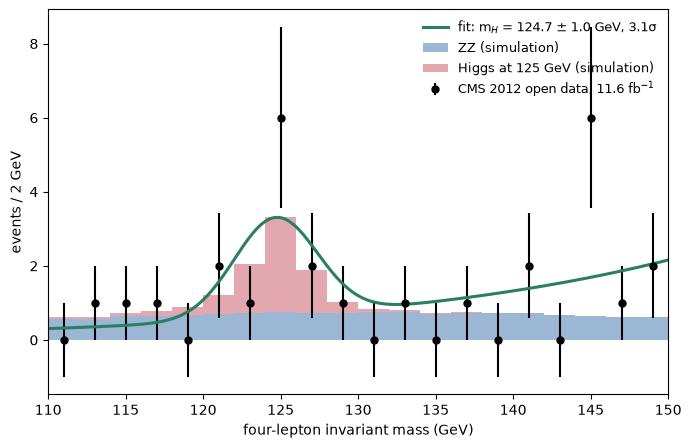

In [6]:
mH, slope, ns, nb = res.x; xs = np.linspace(WLO, WHI, 400)
curve = (ns * np.exp(-0.5 * ((xs - mH) / sigma)**2) / (sigma * np.sqrt(2 * np.pi)) + nb * slope * np.exp(slope * (xs - WLO)) / (np.exp(slope * (WHI - WLO)) - 1.0)) * 2
edges = np.arange(WLO, WHI + 2, 2); mw = (sig > WLO) & (sig < WHI); mb = (bkg > WLO) & (bkg < WHI)
fig, ax = plt.subplots(figsize=(8, 5)); hb, _ = np.histogram(bkg[mb], bins=edges, weights=bkg_w[mb]); hs, _ = np.histogram(sig[mw], bins=edges, weights=sig_w[mw]); cnt, _ = np.histogram(m, bins=edges)
ax.bar(edges[:-1], hb, width=2, align="edge", color="#9bb7d4", label="ZZ (simulation)"); ax.bar(edges[:-1], hs, width=2, bottom=hb, align="edge", color="#e3a7b0", label="Higgs at 125 GeV (simulation)")
ax.errorbar(edges[:-1] + 1, cnt, yerr=np.sqrt(np.maximum(cnt, 1)), fmt="o", color="black", ms=5, label="CMS 2012 open data, 11.6 fb$^{-1}$")
ax.plot(xs, curve, color="#2a7f62", lw=2.2, label=f"fit: m$_H$ = {mH:.1f} ± {err[0]:.1f} GeV, {np.sqrt(max(q0, 0)):.1f}σ")
ax.set_xlabel("four-lepton invariant mass (GeV)"); ax.set_ylabel("events / 2 GeV"); ax.set_xlim(WLO, WHI); ax.legend(frameon=False, fontsize=9); plt.show()

## What this is and is not

Local significance, one window, one selection, 28 events. The 2012 observation combined more channels and more data. What you did reproduce: the mass, within a GeV, from the events themselves, with a likelihood you can read in full.

In the talk, the likelihood was not written by hand: RooFit emitted it as C++ and Clad wrote its gradient, so Minuit2 and JAX both ran on the physicists' own model. That path needs ROOT; it is in `../notebooks/nb5_higgs_open_data.ipynb`.

## Play with it

- Move the window (`WLO, WHI`) or free the signal width and see what 28 events can and cannot pin down.
- Replace the exponential with a flat background. Does the mass move? Does the significance?
- Fit each channel (`4mu`, `4el`, `2el2mu`) on its own.

Next: a tiny model with the cancer model's shape, stepped, steered and calibrated from Python, `5_tiny_twin.ipynb`.